# Rice leaf disease classification — Simple CNN
### Train from scratch on Modal.com • 224 × 224 RGB • Six classes

This notebook implements your requested **32 → 64 → 128 convolution architecture**, with global
average pooling, Dense(128), Dropout and Dense(6)/Softmax. All weights start randomly.
It uses the image audit, preprocessing and group-aware split approach from your supplied
MobileNetV3 notebook. There is **no pretrained backbone and no fine-tuning stage**.

**Before running**
1. Import this file at [Modal Notebooks](https://modal.com/notebooks).
2. In kernel settings select **one L4 GPU**, **4 CPU cores**, and **16 GiB RAM** as a starting configuration.
3. Attach a Volume in the Files panel. Upload `data.zip` there and copy the actual `/mnt/...` path.
4. Run installation once. If a restart is requested, restart and continue at step 2 below.
5. Edit the configuration paths, then run the remaining cells in order. Inspect the image previews.
6. Download `rice_leaf_simple_cnn_bundle.zip` from the Files panel after training, then stop the kernel.

**Persistent storage:** `/root` is temporary. Use an attached Volume for the dataset, checkpoints
and results. See [Modal's notebook guide](https://modal.com/docs/guide/notebooks).

**Fair comparison:** upload the old `reports/split_manifest.csv` from your MobileNetV3 model bundle
and set `PREVIOUS_SPLIT_CSV`. Matching only the seed or split counts does not establish an identical split.
Your supplied notebook recorded **89.3733% test accuracy on 734 images**; that is a previous result,
not a promised CNN score. This new notebook has no trained results yet.


## 1 · Install the training environment
Use a dedicated Linux Python 3.10–3.13 notebook. The versions match the environment used in your
example, rather than claiming to be the newest releases. This removes JAX/JAXlib from this
dedicated kernel to avoid competing XLA libraries. It installs TensorFlow's GPU dependencies.
[TensorFlow installation reference](https://www.tensorflow.org/install/pip).


In [1]:
import sys, subprocess, shutil, importlib.metadata as package_metadata

if not ((3, 10) <= sys.version_info[:2] <= (3, 13)):
    raise RuntimeError("Use a Python 3.10–3.13 kernel for the pinned TensorFlow environment.")
if not sys.platform.startswith("linux"):
    raise RuntimeError("This installation cell targets Modal's Linux notebook kernel.")
requirements = [
    "tensorflow[and-cuda]==2.20.0", "keras==3.11.3",
    "numpy==2.2.6", "pandas==2.2.3", "Pillow==11.3.0",
    "scikit-learn==1.7.2", "matplotlib==3.10.6", "scipy==1.15.3",
]
def installed_version(package):
    try:
        return package_metadata.version(package)
    except package_metadata.PackageNotFoundError:
        return None

module_names = {"scikit-learn": "sklearn", "Pillow": "PIL"}
loaded_before_install = "jax" in sys.modules or "jaxlib" in sys.modules
for requirement in requirements:
    package, version = requirement.split("==")
    package = package.split("[")[0]
    module = module_names.get(package, package)
    if module in sys.modules and installed_version(package) != version:
        loaded_before_install = True
uv = shutil.which("uv")
# uv's --python option belongs to the install/uninstall subcommand.
def package_command(action, packages):
    if uv:
        return [uv, "pip", action, "--python", sys.executable, *packages]
    return [sys.executable, "-m", "pip", action, *(["-y"] if action == "uninstall" else []), *packages]

installed = {d.metadata["Name"].lower() for d in package_metadata.distributions() if d.metadata["Name"]}
jax_packages = [p for p in ("jax", "jaxlib") if p in installed]
if jax_packages:
    subprocess.check_call(package_command("uninstall", jax_packages))
subprocess.check_call(package_command("install", requirements))
print("Installation complete.")
if loaded_before_install:
    raise RuntimeError("Restart the kernel now to load the installed libraries, then continue at step 2.")
print("Continue at step 2. Reinstall only after a new container starts.")


Installation complete.
Continue at step 2. Reinstall only after a new container starts.


Using Python 3.12.6 environment at: /usr/local
Audited 8 packages in 11ms


## 2 · Configuration — edit the paths here
`VOLUME_ROOT` must be the actual attached Volume folder, not `/mnt` itself.
The ZIP may contain the six class folders directly or inside a parent folder.
Use a **new RUN_NAME** when changing settings. Reusing an unchanged run resumes an epoch backup,
or loads the best model if training already completed. Never run two kernels against the same run folder.

The defaults are 80 maximum epochs, Adam at 0.001, dropout 0.30 and light L2 regularization.
Validation loss selects the checkpoint, reduces the learning rate and stops training early.
These are starting settings, not an accuracy guarantee. Tune using validation results only.


In [2]:
from pathlib import Path
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# EDIT THESE PATHS using the Modal Files panel.
VOLUME_ROOT = Path("/root")
ZIP_PATH = VOLUME_ROOT / "data.zip"
PROJECT_DIR = VOLUME_ROOT / "rice_simple_cnn"
RUN_NAME = "simple_cnn_run_01"

# Strongly recommended for comparison: upload the old split_manifest.csv.
PREVIOUS_SPLIT_CSV = None  # Example: VOLUME_ROOT / "mobilenet_split_manifest.csv"
GROUP_METADATA_CSV = None  # Optional CSV: relative_path,group_id (same plant/session/farm).
SEED = 42
BATCH_SIZE = 32
EPOCHS = 80
LEARNING_RATE = 1e-3
DROPOUT = 0.30
L2_REGULARIZATION = 1e-4
EARLY_STOPPING_PATIENCE = 12
LR_PATIENCE = 4
USE_CLASS_WEIGHTS = True
EXPORT_TFLITE = True
REQUIRE_GPU = True
if not VOLUME_ROOT.is_dir():
    raise FileNotFoundError(f"Folder not found: {VOLUME_ROOT}")

if VOLUME_ROOT == Path("/root"):
    print(
        "Using temporary storage. Download the trained model "
        "and results before stopping the kernel."
    )
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Upload your dataset ZIP or fix ZIP_PATH: {ZIP_PATH}")
for optional_path in (PREVIOUS_SPLIT_CSV, GROUP_METADATA_CSV):
    if optional_path is not None and not Path(optional_path).is_file():
        raise FileNotFoundError(optional_path)
if not PROJECT_DIR.resolve().is_relative_to(VOLUME_ROOT.resolve()):
    raise ValueError("PROJECT_DIR must be inside the attached Volume.")
if Path(RUN_NAME).name != RUN_NAME or RUN_NAME in ("", ".", ".."):
    raise ValueError("RUN_NAME must be a simple folder name.")
assert BATCH_SIZE > 0 and EPOCHS > 0 and LEARNING_RATE > 0
assert 0 <= DROPOUT < 1 and L2_REGULARIZATION >= 0
RUN_DIR = PROJECT_DIR / "runs" / RUN_NAME
REPORT_DIR = RUN_DIR / "reports"
EXPORT_DIR = RUN_DIR / "export"
for folder in (RUN_DIR, REPORT_DIR, EXPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Results:", RUN_DIR)


Using temporary storage. Download the trained model and results before stopping the kernel.
Results: /root/rice_simple_cnn/runs/simple_cnn_run_01


## 3 · Verify TensorFlow sees the GPU


In [3]:
import sys, json, random, platform, importlib.metadata, subprocess
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy("float32")
gpus = tf.config.list_physical_devices("GPU")
if REQUIRE_GPU and not gpus:
    raise RuntimeError(
        "TensorFlow cannot see a GPU. Select L4 in kernel settings, rerun installation "
        "in the new container, and restart the kernel. Do not continue on CPU by accident."
    )
for device in gpus:
    tf.config.experimental.set_memory_growth(device, True)
tf.config.experimental.enable_op_determinism()
print("TensorFlow:", tf.__version__, "| Keras:", tf.keras.__version__)
print("GPU devices:", gpus)
print("Class input: 224 × 224 RGB, float32 in [0,255]. Normalization is inside the model.")
freeze = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"], text=True, capture_output=True)
if freeze.returncode == 0:
    (REPORT_DIR / "environment.txt").write_text(freeze.stdout)
else:
    (REPORT_DIR / "environment.txt").write_text("\n".join(
        f"{d.metadata['Name']}=={d.version}" for d in importlib.metadata.distributions()
        if d.metadata["Name"]))


TensorFlow: 2.20.0 | Keras: 3.11.3
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Class input: 224 × 224 RGB, float32 in [0,255]. Normalization is inside the model.


## 4 · Audit and prepare the dataset
Accepted labels, in output order:
`Bacterial Leaf Blight`, `Brown Spot`, `Healthy Rice Leaf`, `Leaf Blast`, `Leaf scald`, `Sheath Blight`.
Folder matching ignores spaces, underscores and case. Images may be JPEG, PNG, BMP, WebP or single-frame TIFF.

The audit decodes each image, removes exact pixel duplicates, stops on conflicting labels,
and reports unreadable files. It applies EXIF orientation, converts to RGB and resizes with
aspect ratio preserved on a black 224 × 224 canvas, matching your original preprocessing.
Near duplicates and optional capture groups are kept within one split. This reduces leakage;
it cannot identify every related photo or establish performance on independent farms.


In [4]:
import hashlib
import json
import os
import re
import shutil
import stat
import zipfile
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

CLASS_NAMES = [
    "Bacterial Leaf Blight", "Brown Spot", "Healthy Rice Leaf",
    "Leaf Blast", "Leaf scald", "Sheath Blight",
]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
CLASS_LOOKUP = {re.sub(r"[^a-z0-9]", "", n.lower()): n for n in CLASS_NAMES}


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


def extract_checked(archive, destination, max_bytes=30 * 1024**3):
    """No extraction outside destination; no symlinks or duplicate member names."""
    destination = Path(destination).resolve()
    marker = destination / ".extracted.json"
    archive_hash = sha256_file(archive)
    if marker.exists():
        if json.loads(marker.read_text())["sha256"] == archive_hash:
            return destination, archive_hash
        raise ValueError("Archive changed. Use a new PROJECT_DIR to preserve previous runs.")
    if destination.exists() and any(destination.iterdir()):
        raise ValueError("Incomplete extraction found. Choose a new PROJECT_DIR.")
    with zipfile.ZipFile(archive) as z:
        members = z.infolist()
        if len(members) > 100_000 or sum(m.file_size for m in members) > max_bytes:
            raise ValueError("Archive exceeds the configured extraction limit.")
        seen = set()
        for member in members:
            name = member.filename.replace("\\", "/")
            relative = PurePosixPath(name)
            mode = member.external_attr >> 16
            if (relative.is_absolute() or ".." in relative.parts or
                    not relative.parts or ":" in relative.parts[0] or
                    stat.S_ISLNK(mode)):
                raise ValueError(f"Unsafe ZIP entry: {member.filename}")
            target = (destination / str(relative)).resolve()
            if not target.is_relative_to(destination):
                raise ValueError(f"Unsafe ZIP entry: {member.filename}")
            if str(relative) in seen:
                raise ValueError(f"Repeated ZIP path: {member.filename}")
            seen.add(str(relative))
        destination.mkdir(parents=True, exist_ok=True)
        for member in members:
            target = destination / member.filename.replace("\\", "/")
            if member.is_dir():
                target.mkdir(parents=True, exist_ok=True)
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(member) as source, open(target, "wb") as sink:
                    shutil.copyfileobj(source, sink)
    write_json(marker, {"sha256": archive_hash})
    return destination, archive_hash


def open_rgb(path):
    with Image.open(path) as source:
        if getattr(source, "n_frames", 1) != 1:
            raise ValueError("Multi-frame image: select one frame manually.")
        image = ImageOps.exif_transpose(source)
        if image.mode in ("RGBA", "LA") or "transparency" in image.info:
            rgba = image.convert("RGBA")
            background = Image.new("RGBA", rgba.size, (0, 0, 0, 255))
            image = Image.alpha_composite(background, rgba)
        return image.convert("RGB").copy()


def letterbox(image, size=224):
    scaled = ImageOps.contain(image, (size, size), Image.Resampling.BILINEAR)
    output = Image.new("RGB", (size, size), (0, 0, 0))
    output.paste(scaled, ((size - scaled.width) // 2, (size - scaled.height) // 2))
    return output


def dhash(image):
    gray = np.asarray(image.convert("L").resize((9, 8), Image.Resampling.BILINEAR))
    bits = (gray[:, 1:] > gray[:, :-1]).ravel()
    return int.from_bytes(np.packbits(bits).tobytes(), "big")


def build_inventory(raw_dir, cache_dir, report_dir):
    """Decode every image, quarantine broken/unknown entries, and remove exact repeats."""
    raw_dir, cache_dir, report_dir = map(Path, (raw_dir, cache_dir, report_dir))
    cache_dir.mkdir(parents=True, exist_ok=True)
    rows, rejected, duplicates, conflicts = [], [], [], []
    fingerprints = {}
    thumbnails = {}
    for path in sorted(raw_dir.rglob("*")):
        if not path.is_file() or "__MACOSX" in path.parts or path.name.startswith("."):
            continue
        relative = path.relative_to(raw_dir).as_posix()
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        matched = {
            CLASS_LOOKUP[normalized]
            for part in path.relative_to(raw_dir).parts[:-1]
            if (normalized := re.sub(r"[^a-z0-9]", "", part.lower())) in CLASS_LOOKUP
        }
        if len(matched) != 1:
            rejected.append({"relative_path": relative, "reason": "Unknown or ambiguous class folder"})
            continue
        label = matched.pop()
        try:
            rgb = open_rgb(path)
            digest = hashlib.sha256(
                f"{rgb.width},{rgb.height}:".encode() + rgb.tobytes()
            ).hexdigest()
            if digest in fingerprints:
                first = fingerprints[digest]
                duplicate = {
                    "relative_path": relative, "kept_path": first["relative_path"],
                    "label": label, "kept_label": first["label"],
                }
                if first["label"] != label:
                    conflicts.append(duplicate)
                else:
                    duplicates.append(duplicate)
                continue
            cached = cache_dir / f"{digest}.png"
            letterbox(rgb).save(cached)
            row = {
                "relative_path": relative, "image_path": str(cached),
                "label": label, "label_id": CLASS_NAMES.index(label),
                "width": rgb.width, "height": rgb.height,
                "pixel_sha256": digest, "dhash": str(dhash(rgb)),
                "small_image": min(rgb.size) < 128,
            }
            fingerprints[digest] = row
            rows.append(row)
            thumbnails[digest] = np.asarray(
                rgb.resize((16, 16), Image.Resampling.BILINEAR), dtype=np.int16
            )
        except (OSError, ValueError, Image.DecompressionBombError) as exc:
            rejected.append({"relative_path": relative, "reason": str(exc)})
    pd.DataFrame(rejected, columns=["relative_path", "reason"]).to_csv(
        report_dir / "rejected_images.csv", index=False)
    for name, entries in [("exact_duplicates", duplicates), ("label_conflicts", conflicts)]:
        pd.DataFrame(entries, columns=[
            "relative_path", "kept_path", "label", "kept_label"
        ]).to_csv(report_dir / f"{name}.csv", index=False)
    frame = pd.DataFrame(rows)
    frame.to_csv(report_dir / "inventory.csv", index=False)
    if conflicts:
        raise ValueError("Identical images have different labels. Resolve label_conflicts.csv first.")
    if frame.empty:
        raise ValueError("No readable images found inside the six recognized class folders.")
    missing = set(CLASS_NAMES) - set(frame.label)
    if missing:
        raise ValueError(f"Missing classes: {sorted(missing)}. Check folder spelling.")
    return frame.reset_index(drop=True), thumbnails


class UnionFind:
    def __init__(self, count):
        self.parent = list(range(count))

    def find(self, index):
        while self.parent[index] != index:
            self.parent[index] = self.parent[self.parent[index]]
            index = self.parent[index]
        return index

    def union(self, left, right):
        left, right = self.find(left), self.find(right)
        if left != right:
            self.parent[right] = left


class BKTree:
    """Hamming-distance search over 64-bit perceptual hashes."""
    def __init__(self):
        self.root = None

    def insert(self, value, index):
        if self.root is None:
            self.root = [value, [index], {}]
            return
        node = self.root
        while True:
            distance = (value ^ node[0]).bit_count()
            if distance == 0:
                node[1].append(index)
                return
            if distance not in node[2]:
                node[2][distance] = [value, [index], {}]
                return
            node = node[2][distance]

    def search(self, value, radius):
        stack = [self.root] if self.root is not None else []
        while stack:
            node = stack.pop()
            distance = (value ^ node[0]).bit_count()
            if distance <= radius:
                yield from node[1]
            stack.extend(child for edge, child in node[2].items()
                         if distance - radius <= edge <= distance + radius)


def add_groups(frame, thumbnails, metadata_csv=None):
    frame = frame.copy().reset_index(drop=True)
    union, tree = UnionFind(len(frame)), BKTree()
    near_pairs = []
    for index, row in enumerate(frame.itertuples()):
        value = int(row.dhash)
        for other in tree.search(value, 3):
            previous = frame.iloc[other]
            aspect_difference = abs(np.log(
                (row.width / row.height) / (previous.width / previous.height)))
            difference = float(np.abs(
                thumbnails[row.pixel_sha256] - thumbnails[previous.pixel_sha256]
            ).mean())
            if aspect_difference < 0.05 and difference <= 12:
                union.union(index, other)
                near_pairs.append({
                    "left": row.relative_path, "right": previous.relative_path,
                    "left_label": row.label, "right_label": previous.label,
                    "thumbnail_difference": difference,
                })
        tree.insert(value, index)
    if metadata_csv:
        metadata = pd.read_csv(metadata_csv, dtype=str).fillna("")
        if not {"relative_path", "group_id"} <= set(metadata.columns):
            raise ValueError("Group metadata needs relative_path and group_id columns.")
        if metadata.relative_path.duplicated().any():
            raise ValueError("Group metadata has repeated relative_path values.")
        mapping = dict(zip(metadata.relative_path, metadata.group_id))
        unmatched = set(mapping) - set(frame.relative_path)
        if unmatched:
            print(f"Metadata paths absent after cleaning: {len(unmatched)}")
        first_member = {}
        for index, path in enumerate(frame.relative_path):
            group = mapping.get(path, "").strip()
            if group:
                if group in first_member:
                    union.union(index, first_member[group])
                else:
                    first_member[group] = index
        frame["capture_group_known"] = [
            bool(mapping.get(path, "").strip()) for path in frame.relative_path
        ]
    else:
        frame["capture_group_known"] = False
    frame["group_id"] = [f"group_{union.find(i):06d}" for i in range(len(frame))]
    return frame, pd.DataFrame(near_pairs, columns=[
        "left", "right", "left_label", "right_label", "thumbnail_difference"
    ])


def grouped_split(frame, seed=42, trials=600):
    """Search reproducible group assignments using labels only, never model results."""
    frame = frame.copy()
    table = pd.crosstab(frame.group_id, frame.label_id).reindex(
        columns=range(len(CLASS_NAMES)), fill_value=0)
    counts = table.to_numpy()
    if ((counts > 0).sum(axis=0) < 10).any():
        raise ValueError("Fewer than 10 independent groups in a class. Collect more groups.")
    proportions = np.array([0.70, 0.15, 0.15])
    desired = proportions[:, None] * counts.sum(axis=0)[None, :]
    rng, best = np.random.default_rng(seed), None
    best_error = float("inf")
    for _ in range(trials):
        assignment = rng.choice(3, len(counts), p=proportions)
        actual = np.zeros_like(desired)
        np.add.at(actual, assignment, counts)
        if actual.min() < 3:
            continue
        error = float(np.square((actual - desired) / np.maximum(desired, 1)).mean())
        if error < best_error:
            best, best_error = assignment, error
    if best is None:
        raise ValueError("Unable to create three usable grouped splits. Inspect group sizes.")
    mapping = dict(zip(table.index, np.array(["train", "validation", "test"])[best]))
    frame["split"] = frame.group_id.map(mapping)
    if frame.groupby("group_id").split.nunique().max() != 1:
        raise AssertionError("Group leakage detected.")
    if frame.groupby("pixel_sha256").split.nunique().max() != 1:
        raise AssertionError("Duplicate leakage detected.")
    return frame


In [5]:
archive_sha256 = sha256_file(ZIP_PATH)
DATA_DIR = PROJECT_DIR / "datasets" / archive_sha256[:16]
RAW_DIR = DATA_DIR / "raw"
CACHE_DIR = DATA_DIR / "rgb224"
print("Checking and extracting the ZIP...")
_, verified_archive_hash = extract_checked(ZIP_PATH, RAW_DIR)
assert verified_archive_hash == archive_sha256
inventory, thumbnails = build_inventory(RAW_DIR, CACHE_DIR, REPORT_DIR)
display(inventory.groupby("label").agg(
    usable_images=("relative_path", "size"),
    small_images=("small_image", "sum")).reindex(CLASS_NAMES))
print("Usable images:", len(inventory))
print("Read rejected_images.csv and exact_duplicates.csv in", REPORT_DIR)
template = inventory[["relative_path"]].copy()
template["group_id"] = ""
template.to_csv(REPORT_DIR / "capture_groups_template.csv", index=False)


Checking and extracting the ZIP...


,usable_images,small_images
label,,
Bacterial Leaf Blight,675,0
Brown Spot,1612,6
Healthy Rice Leaf,643,0
Leaf Blast,619,0
Leaf scald,628,0
Sheath Blight,628,0


Usable images: 4805
Read rejected_images.csv and exact_duplicates.csv in /root/rice_simple_cnn/runs/simple_cnn_run_01/reports


## 5 · Review labels and lock the split
Inspect these examples and the audit CSV files before training. If labels or images are wrong,
correct the dataset first. New splits target approximately 70% train, 15% validation and 15% test;
grouping means exact counts can differ.

If `PREVIOUS_SPLIT_CSV` is supplied, every cleaned image must match by pixel hash and label.
The old assignments are reused, with fresh local image paths. The notebook stops if those
assignments split a detected group. It never silently substitutes a different test set.


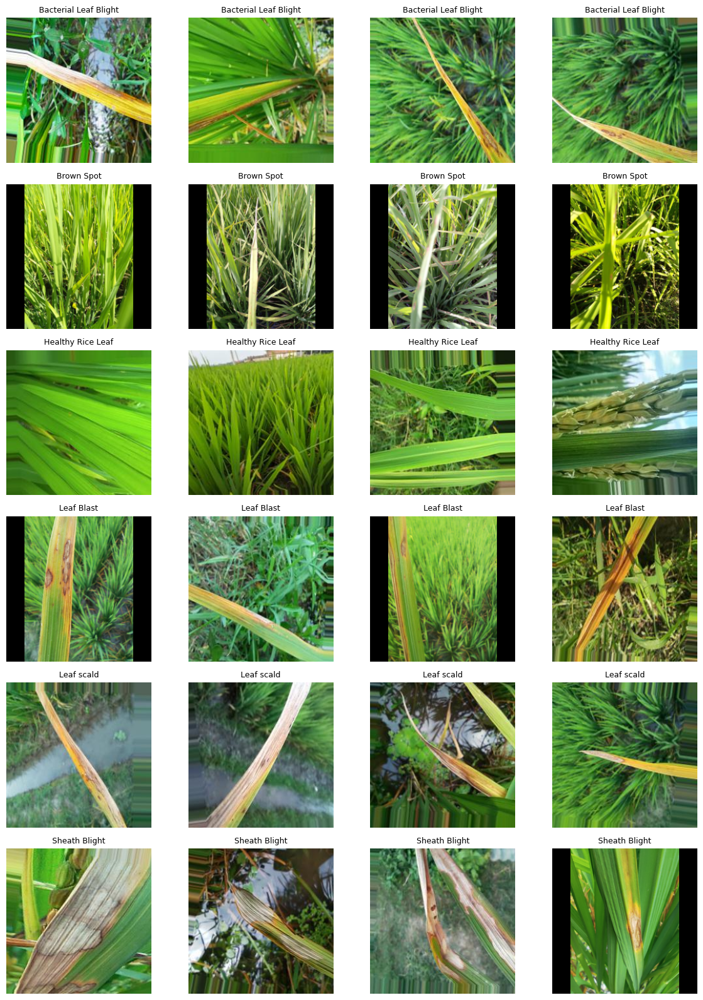

In [6]:
fig, axes = plt.subplots(6, 4, figsize=(12, 16))
for row_index, label in enumerate(CLASS_NAMES):
    candidates = inventory[inventory.label == label].sample(
        min(4, sum(inventory.label == label)), random_state=SEED)
    for axis in axes[row_index]:
        axis.axis("off")
    for column, row in enumerate(candidates.itertuples()):
        axes[row_index, column].imshow(Image.open(row.image_path))
        axes[row_index, column].set_title(label, fontsize=9)
fig.tight_layout()
fig.savefig(REPORT_DIR / "dataset_samples.png", dpi=120)
plt.show()


In [7]:
def apply_existing_split(frame, csv_path):
    previous = pd.read_csv(csv_path, dtype={"pixel_sha256": str})
    required = {"pixel_sha256", "label", "split"}
    if not required <= set(previous.columns):
        raise ValueError(f"Split CSV needs columns: {sorted(required)}")
    if previous.pixel_sha256.duplicated().any():
        raise ValueError("Split CSV contains repeated image hashes.")
    if set(previous.pixel_sha256) != set(frame.pixel_sha256):
        raise ValueError("Previous split and cleaned dataset differ. Use the exact original dataset.")
    previous = previous.set_index("pixel_sha256")
    aligned = previous.loc[frame.pixel_sha256]
    if not np.array_equal(aligned.label.to_numpy(), frame.label.to_numpy()):
        raise ValueError("Labels differ from the previous experiment.")
    result = frame.copy()
    result["split"] = aligned.split.to_numpy()
    if "group_id" in previous:
        old_group_check = aligned[["group_id", "split"]]
        if old_group_check.groupby("group_id").split.nunique().max() != 1:
            raise ValueError("Previous split has group leakage.")
    validate_split(result)
    return result

def validate_split(frame):
    if set(frame.split) != {"train", "validation", "test"}:
        raise ValueError("Expected exactly train, validation and test assignments.")
    if frame.groupby("group_id").split.nunique().max() != 1:
        raise ValueError("A related-image group crosses splits. Review grouping or the old split.")
    if frame.groupby("pixel_sha256").split.nunique().max() != 1:
        raise ValueError("An identical image crosses splits.")
    counts = pd.crosstab(frame.label, frame.split).reindex(CLASS_NAMES, fill_value=0)
    if (counts <= 0).any().any():
        raise ValueError("Each class must be represented in every split.")

grouped, near_pairs = add_groups(inventory, thumbnails, GROUP_METADATA_CSV)
near_pairs.to_csv(REPORT_DIR / "near_duplicates.csv", index=False)
print("Near-duplicate pairs grouped:", len(near_pairs))
print("Known capture-group coverage:", f"{grouped.capture_group_known.mean():.1%}")

experiment_config = {
    "pipeline_version": "simple-cnn-1.0", "architecture": "conv32-conv64-conv128-gap-dense128-dropout-softmax6",
    "archive_sha256": archive_sha256, "seed": SEED,
    "metadata_sha256": sha256_file(GROUP_METADATA_CSV) if GROUP_METADATA_CSV else None,
    "previous_split_sha256": sha256_file(PREVIOUS_SPLIT_CSV) if PREVIOUS_SPLIT_CSV else None,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "learning_rate": LEARNING_RATE,
    "dropout": DROPOUT, "l2": L2_REGULARIZATION,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE, "lr_patience": LR_PATIENCE,
    "class_weights": USE_CLASS_WEIGHTS, "class_names": CLASS_NAMES,
    "tensorflow": tf.__version__, "keras": tf.keras.__version__,
}
config_path = RUN_DIR / "experiment_config.json"
if config_path.exists() and json.loads(config_path.read_text()) != experiment_config:
    raise ValueError("Settings changed. Choose a NEW RUN_NAME to preserve previous results.")
manifest_path = REPORT_DIR / "split_manifest.csv"
if manifest_path.exists():
    manifest = apply_existing_split(grouped, manifest_path)
elif PREVIOUS_SPLIT_CSV is not None:
    manifest = apply_existing_split(grouped, PREVIOUS_SPLIT_CSV)
else:
    manifest = grouped_split(grouped, seed=SEED)
validate_split(manifest)
write_json(config_path, experiment_config)
manifest.to_csv(manifest_path, index=False)
train_frame = manifest[manifest.split == "train"].reset_index(drop=True)
validation_frame = manifest[manifest.split == "validation"].reset_index(drop=True)
test_frame = manifest[manifest.split == "test"].reset_index(drop=True)
display(pd.crosstab(manifest.label, manifest.split).reindex(CLASS_NAMES)[["train", "validation", "test"]])
print("Reused the supplied previous split:", PREVIOUS_SPLIT_CSV is not None)
print("Test images are reserved for final evaluation.")


Near-duplicate pairs grouped: 247
Known capture-group coverage: 0.0%


split,train,validation,test
label,,,
Bacterial Leaf Blight,468,102,105
Brown Spot,1138,228,246
Healthy Rice Leaf,443,101,99
Leaf Blast,427,96,96
Leaf scald,438,94,96
Sheath Blight,441,95,92


Reused the supplied previous split: False
Test images are reserved for final evaluation.


## 6 · Training-only augmentation and class balancing
Only training images receive flips, small rotations, zoom, contrast and brightness changes.
Validation/test inputs stay deterministic. Class weights are computed from training labels only
when enabled and the largest class is over 1.5 times the smallest. Inspect the preview:
the augmentation should preserve visible disease symptoms.


In [8]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    tf.keras.layers.RandomRotation(0.08, fill_mode="constant", fill_value=0, seed=SEED + 1),
    tf.keras.layers.RandomZoom(0.10, fill_mode="constant", fill_value=0, seed=SEED + 2),
    tf.keras.layers.RandomContrast(0.10, seed=SEED + 3),
    tf.keras.layers.RandomBrightness(0.10, value_range=(0, 255), seed=SEED + 4),
], name="training_augmentation")


I0000 00:00:1792265254.007872     280 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 20813 MB memory:  -> device: 0, name: NVIDIA A10, pci bus id: 0000:17:00.0, compute capability: 8.6


In [9]:
import time
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_recall_fscore_support,
)


def decode_cached(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.ensure_shape(image, (224, 224, 3))
    return tf.cast(image, tf.float32), label


def make_dataset(frame, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        frame.image_path.astype(str).to_numpy(),
        frame.label_id.to_numpy(dtype=np.int32),
    ))
    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(decode_cached, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    if training:
        dataset = dataset.map(
            lambda x, y: (tf.clip_by_value(augmentation(x, training=True), 0, 255), y),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    options = tf.data.Options()
    options.experimental_deterministic = True
    return dataset.with_options(options).prefetch(tf.data.AUTOTUNE)


def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
        jit_compile=False,
    )


class SyncPersistentStorage(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if hasattr(os, "sync"):
            os.sync()


def fit_stage(model, stage_name, epochs):
    stage_dir = RUN_DIR / stage_name
    stage_dir.mkdir(exist_ok=True)
    checkpoint = stage_dir / "best.keras"
    completed = stage_dir / "complete.json"
    log_path = stage_dir / "history.csv"
    if completed.exists() and checkpoint.exists():
        print(f"{stage_name}: already complete; using its saved best checkpoint.")
        return tf.keras.models.load_model(checkpoint, compile=False)
    initial_best = None
    if log_path.exists() and checkpoint.exists():
        previous = pd.read_csv(log_path).drop_duplicates("epoch", keep="last")
        if "val_loss" in previous and len(previous):
            initial_best = float(previous.val_loss.min())
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(checkpoint), monitor="val_loss", mode="min",
            save_best_only=True, initial_value_threshold=initial_best, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=LR_PATIENCE,
            min_lr=1e-6, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=EARLY_STOPPING_PATIENCE, min_delta=0.0001,
            restore_best_weights=False, verbose=1,
        ),
        tf.keras.callbacks.TerminateOnNaN(),
        tf.keras.callbacks.CSVLogger(str(log_path), append=log_path.exists()),
        tf.keras.callbacks.BackupAndRestore(
            backup_dir=str(stage_dir / "resume"), save_freq="epoch",
            delete_checkpoint=False, double_checkpoint=True,
        ),
        SyncPersistentStorage(),
    ]
    model.fit(
        train_ds, validation_data=validation_ds, epochs=epochs,
        class_weight=class_weights, callbacks=callbacks, verbose=2,
    )
    if not checkpoint.exists():
        raise RuntimeError("Training did not produce a finite best checkpoint.")
    history = pd.read_csv(log_path).drop_duplicates("epoch", keep="last")
    if not np.isfinite(history[["loss", "val_loss"]].to_numpy()).all():
        raise RuntimeError("Non-finite training loss. Inspect logs and retry with a lower learning rate in a new run.")
    write_json(completed, {"checkpoint": str(checkpoint)})
    if hasattr(os, "sync"):
        os.sync()
    return tf.keras.models.load_model(checkpoint, compile=False)


def predict_frame(model, frame):
    predictions = model.predict(make_dataset(frame), verbose=0)
    if not np.isfinite(predictions).all():
        raise ValueError("Non-finite predictions.")
    return predictions


def metrics_for(frame, probabilities):
    true = frame.label_id.to_numpy(dtype=int)
    predicted = probabilities.argmax(axis=1)
    probabilities = np.clip(probabilities, 1e-7, 1)
    return {
        "images": int(len(frame)),
        "accuracy": float(accuracy_score(true, predicted)),
        "balanced_accuracy": float(balanced_accuracy_score(true, predicted)),
        "macro_f1": float(f1_score(true, predicted, average="macro", zero_division=0)),
        "cross_entropy": float(-np.log(probabilities[np.arange(len(true)), true]).mean()),
    }


def save_predictions(frame, probabilities, path):
    output = frame[["relative_path", "label", "label_id", "group_id", "split"]].copy()
    output["predicted_class"] = np.array(CLASS_NAMES)[probabilities.argmax(axis=1)]
    output["score"] = probabilities.max(axis=1)
    for index, name in enumerate(CLASS_NAMES):
        output[f"score_{name}"] = probabilities[:, index]
    output.to_csv(path, index=False)


Class weights: {0: 1.1948005698005697, 1: 0.4913591095489162, 2: 1.262227238525207, 3: 1.3095238095238095, 4: 1.2766362252663623, 5: 1.2679516250944822}


2026-10-17 19:28:01.080637: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


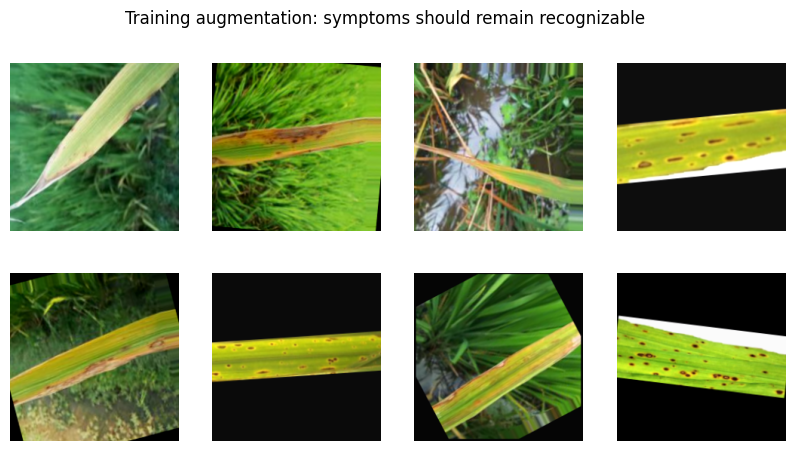

In [10]:
train_ds = make_dataset(train_frame, training=True)
validation_ds = make_dataset(validation_frame)
counts = train_frame.label_id.value_counts().sort_index()
class_weights = (
    {int(k): float(len(train_frame) / (6 * v)) for k, v in counts.items()}
    if USE_CLASS_WEIGHTS and counts.max() / counts.min() > 1.5 else None
)
print("Class weights:", class_weights or "not needed")
preview_images, _ = next(iter(train_ds))
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for index, axis in enumerate(axes.flat):
    axis.imshow(preview_images[index % len(preview_images)].numpy().astype("uint8"))
    axis.axis("off")
fig.suptitle("Training augmentation: symptoms should remain recognizable")
plt.show()


## 7 · Your exact CNN architecture
| Layer | Output shape, excluding batch |
|---|---|
| RGB input + rescale 1/255 | 224 × 224 × 3 |
| Conv2D 32, 3×3, same padding → ReLU → MaxPool 2×2 | 112 × 112 × 32 |
| Conv2D 64, 3×3, same padding → ReLU → MaxPool 2×2 | 56 × 56 × 64 |
| Conv2D 128, 3×3, same padding → ReLU → MaxPool 2×2 | 28 × 28 × 128 |
| GlobalAveragePooling2D | 128 |
| Dense 128, ReLU → Dropout 0.30 | 128 |
| Dense 6 → Softmax | 6 |

**110,534 trainable parameters.** No batch normalization or additional convolution layers.
The only input normalization is the model's Rescaling layer: pass float32 RGB pixels in **[0,255]**,
including at inference. Do not divide by 255 beforehand.
L2 regularization adds a training penalty without adding layers or parameters.
[Keras Rescaling reference](https://keras.io/api/layers/preprocessing_layers/image_preprocessing/rescaling/).


In [11]:
tf.keras.utils.set_random_seed(SEED)
layers = tf.keras.layers
regularizer = tf.keras.regularizers.l2(L2_REGULARIZATION)
model = tf.keras.Sequential([
    layers.Input(shape=(224, 224, 3), dtype="float32", name="rgb_image"),
    layers.Rescaling(1.0 / 255.0, name="normalize_0_1"),
    layers.Conv2D(32, 3, padding="same", kernel_initializer="he_normal", kernel_regularizer=regularizer, name="conv_32"),
    layers.ReLU(name="relu_32"),
    layers.MaxPooling2D(2, name="pool_32"),
    layers.Conv2D(64, 3, padding="same", kernel_initializer="he_normal", kernel_regularizer=regularizer, name="conv_64"),
    layers.ReLU(name="relu_64"),
    layers.MaxPooling2D(2, name="pool_64"),
    layers.Conv2D(128, 3, padding="same", kernel_initializer="he_normal", kernel_regularizer=regularizer, name="conv_128"),
    layers.ReLU(name="relu_128"),
    layers.MaxPooling2D(2, name="pool_128"),
    layers.GlobalAveragePooling2D(name="global_average_pool"),
    layers.Dense(128, activation="relu", kernel_initializer="he_normal", kernel_regularizer=regularizer, name="dense_128"),
    layers.Dropout(DROPOUT, seed=SEED + 10, name="dropout"),
    layers.Dense(6, name="class_logits"),
    layers.Softmax(name="class_probabilities"),
], name="rice_leaf_simple_cnn")
compile_model(model, LEARNING_RATE)
assert model.count_params() == 110534
assert model.input_shape == (None, 224, 224, 3) and model.output_shape == (None, 6)
probe = model(tf.zeros((1, 224, 224, 3)), training=False).numpy()
assert np.isfinite(probe).all() and np.allclose(probe.sum(axis=1), 1.0)
model.summary()
(REPORT_DIR / "architecture.json").write_text(model.to_json(), encoding="utf-8")
summary_lines = []
model.summary(print_fn=lambda line: summary_lines.append(line))
(REPORT_DIR / "model_summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")


Model: "rice_leaf_simple_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ normalize_0_1 (Rescaling)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_32 (Conv2D)                     │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ relu_32 (ReLU)                       │ (None, 224, 224, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_32 (MaxPooling2D)               │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_64 (Conv2D)                     │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ relu_64 (ReLU)                       │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_64 (MaxPooling2D)               │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_128 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ relu_128 (ReLU)                      │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_128 (MaxPooling2D)              │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pool                  │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_128 (Dense)                    │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ class_logits (Dense)                 │ (None, 6)                   │             774 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ class_probabilities (Softmax)        │ (None, 6)                   │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

3164

## 8 · Train from scratch and reload the best checkpoint
Execute this cell to start GPU training. There is one training stage, up to 80 epochs by default.
The best **validation loss** wins, not the last epoch. Validation loss includes the L2 penalty.

An epoch backup supports interrupted runs with the same configuration. On restart, rerun setup
and data/model cells, then this cell. Callback patience counters and random augmentation state
restart, so resumed training is not guaranteed to match an uninterrupted run bit for bit.
Completed runs load their saved best checkpoint without retraining. Use a new name to start over.
[Keras checkpoint](https://keras.io/api/callbacks/model_checkpoint/) and
[backup documentation](https://keras.io/api/callbacks/backup_and_restore/).


In [12]:
best_model = fit_stage(model, "training", EPOCHS)
best_model.save(EXPORT_DIR / "rice_leaf_simple_cnn.keras")
write_json(EXPORT_DIR / "class_names.json", CLASS_NAMES)
(EXPORT_DIR / "labels.txt").write_text("\n".join(CLASS_NAMES) + "\n", encoding="utf-8")
validation_probabilities = predict_frame(best_model, validation_frame)
validation_metrics = metrics_for(validation_frame, validation_probabilities)
write_json(REPORT_DIR / "validation_metrics.json", validation_metrics)
save_predictions(validation_frame, validation_probabilities, REPORT_DIR / "validation_predictions.csv")
display(pd.DataFrame([validation_metrics]))
print("Saved best model:", EXPORT_DIR / "rice_leaf_simple_cnn.keras")


Epoch 1/80


2026-10-17 19:28:37.332491: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}



Epoch 1: val_loss improved from None to 1.32426, saving model to /root/rice_simple_cnn/runs/simple_cnn_run_01/training/best.keras
105/105 - 35s - 333ms/step - accuracy: 0.3532 - loss: 1.6818 - val_accuracy: 0.5196 - val_loss: 1.3243 - learning_rate: 1.0000e-03
Epoch 2/80

Epoch 2: val_loss improved from 1.32426 to 1.11209, saving model to /root/rice_simple_cnn/runs/simple_cnn_run_01/training/best.keras
105/105 - 30s - 290ms/step - accuracy: 0.5022 - loss: 1.3839 - val_accuracy: 0.5782 - val_loss: 1.1121 - learning_rate: 1.0000e-03
Epoch 3/80

Epoch 3: val_loss improved from 1.11209 to 1.06850, saving model to /root/rice_simple_cnn/runs/simple_cnn_run_01/training/best.keras
105/105 - 31s - 296ms/step - accuracy: 0.5681 - loss: 1.2096 - val_accuracy: 0.6453 - val_loss: 1.0685 - learning_rate: 1.0000e-03
Epoch 4/80

Epoch 4: val_loss improved from 1.06850 to 0.97865, saving model to /root/rice_simple_cnn/runs/simple_cnn_run_01/training/best.keras
105/105 - 30s - 290ms/step - accuracy: 0.

,images,accuracy,balanced_accuracy,macro_f1,cross_entropy
0,716,0.874302,0.879727,0.867958,0.391488


Saved best model: /root/rice_simple_cnn/runs/simple_cnn_run_01/export/rice_leaf_simple_cnn.keras


## 9 · Learning curves
Training uses augmented images, dropout and possibly class-weighted loss; validation does not.
Training/validation losses therefore have different conditions. The displayed cross-entropy
metrics exclude the L2 penalty, unlike the loss curves.

If validation deteriorates while training improves, review labels and overfitting. If both remain
poor, check the dataset and learning rate. Make changes based on validation, then start a new run.
Do not repeatedly change settings to improve the test score.


Best epoch: 71; validation loss: 0.45481


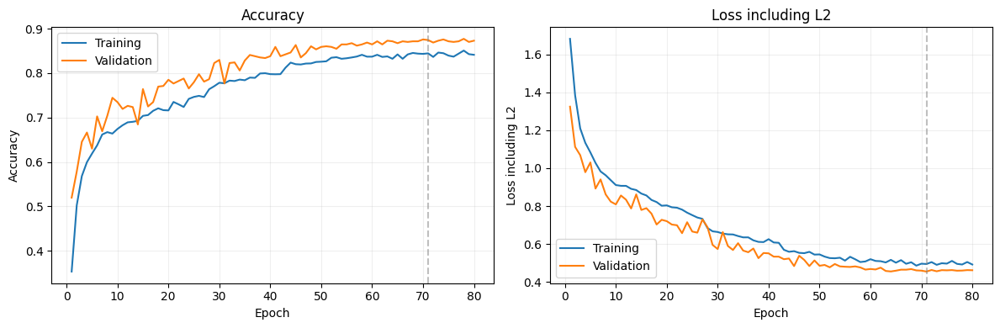

In [13]:
history = pd.read_csv(RUN_DIR / "training" / "history.csv").drop_duplicates("epoch", keep="last").sort_values("epoch")
history.to_csv(REPORT_DIR / "training_history.csv", index=False)
best_row = history.loc[history.val_loss.idxmin()]
print(f"Best epoch: {int(best_row.epoch) + 1}; validation loss: {best_row.val_loss:.5f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, metric, title in zip(axes, ("accuracy", "loss"), ("Accuracy", "Loss including L2")):
    axis.plot(history.epoch + 1, history[metric], label="Training")
    axis.plot(history.epoch + 1, history["val_" + metric], label="Validation")
    axis.axvline(best_row.epoch + 1, color="gray", linestyle="--", alpha=0.5)
    axis.set(xlabel="Epoch", ylabel=title, title=title)
    axis.legend()
    axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(REPORT_DIR / "learning_curves.png", dpi=160)
plt.show()


## 10 · Optional TensorFlow Lite export
The Keras model is already saved. This converts a **float32** mobile model in a separate CPU process
and checks it against Keras on the complete validation set. Failed conversion or parity checks
are recorded without blocking the Keras download. This is a numerical check, not a phone latency test.
Set `EXPORT_TFLITE=False` to skip it. The model accepts the same [0,255] RGB pixels.
[Conversion reference](https://developers.google.com/edge/litert/conversion/tensorflow/convert_tf).


In [14]:
mobile_status = {"requested": EXPORT_TFLITE, "validated": False}
mobile_path = EXPORT_DIR / "rice_leaf_simple_cnn.tflite"

def tflite_predict(model_path, frame):
    interpreter = tf.lite.Interpreter(
        model_path=str(model_path), num_threads=2,
        experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES,
    )
    interpreter.allocate_tensors()
    inp, out = interpreter.get_input_details()[0], interpreter.get_output_details()[0]
    if inp["dtype"] != np.float32 or out["dtype"] != np.float32:
        raise ValueError("Expected float32 input and output.")
    scores = []
    for path in frame.image_path:
        with Image.open(path) as image:
            pixels = np.asarray(image.convert("RGB"), dtype=np.float32)[None]
        interpreter.set_tensor(inp["index"], pixels)
        interpreter.invoke()
        scores.append(interpreter.get_tensor(out["index"])[0])
    return np.asarray(scores)

if EXPORT_TFLITE:
    try:
        saved_model_dir = RUN_DIR / "saved_model"
        best_model.export(str(saved_model_dir), format="tf_saved_model")
        converter_script = RUN_DIR / "convert_tflite.py"
        converter_script.write_text(
            "import sys\nfrom pathlib import Path\nimport tensorflow as tf\n"
            "converter = tf.lite.TFLiteConverter.from_saved_model(sys.argv[1])\n"
            "converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]\n"
            "Path(sys.argv[2]).write_bytes(converter.convert())\n", encoding="utf-8")
        candidate_path = RUN_DIR / "candidate_float32.tflite"
        environment = dict(os.environ, CUDA_VISIBLE_DEVICES="-1", TF_NUM_INTRAOP_THREADS="2", TF_NUM_INTEROP_THREADS="2")
        converted = subprocess.run(
            [sys.executable, str(converter_script), str(saved_model_dir), str(candidate_path)],
            env=environment, capture_output=True, text=True, timeout=600)
        (REPORT_DIR / "conversion.log").write_text(converted.stdout + converted.stderr, encoding="utf-8")
        converted.check_returncode()
        mobile_val = tflite_predict(candidate_path, validation_frame)
        max_error = float(np.max(np.abs(mobile_val - validation_probabilities)))
        agreement = float(np.mean(mobile_val.argmax(1) == validation_probabilities.argmax(1)))
        if not np.isfinite(mobile_val).all() or max_error > 1e-3 or agreement < 0.995:
            raise ValueError(f"Parity failed: max error={max_error}, agreement={agreement}")
        shutil.copy2(candidate_path, mobile_path)
        mobile_status.update(validated=True, max_absolute_error=max_error, validation_agreement=agreement)
        print("Validated mobile export:", mobile_path)
    except Exception as error:
        mobile_status["error"] = str(error)
        print("Mobile export was not approved:", error)
        print("Continue: the Keras model and reports can still be downloaded.")
write_json(REPORT_DIR / "mobile_export_status.json", mobile_status)


INFO:tensorflow:Assets written to: /root/rice_simple_cnn/runs/simple_cnn_run_01/saved_model/assets


INFO:tensorflow:Assets written to: /root/rice_simple_cnn/runs/simple_cnn_run_01/saved_model/assets


Saved artifact at '/root/rice_simple_cnn/runs/simple_cnn_run_01/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='rgb_image')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  47583337043088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47583337043280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47583337038672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47583337043856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47583337043472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47587498120912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47587498119376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47587498121296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47587498120528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47587498117840: TensorSpec(shape=(), dtype=tf.resource, 

/usr/local/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Validated mobile export: /root/rice_simple_cnn/runs/simple_cnn_run_01/export/rice_leaf_simple_cnn.tflite


## 11 · Final test evaluation
Run after architecture and settings are selected. Reports include accuracy, balanced accuracy,
macro F1, per-class precision/recall/F1, a confusion matrix and individual predictions.
The earlier MobileNetV3 result is shown as a historical reference. Only a verified reused split
supports a direct split-matched comparison. Even then, one run does not establish that one
architecture is universally better; repeat seeds and use an independent field set for stronger evidence.


/usr/local/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,images,accuracy,balanced_accuracy,macro_f1,cross_entropy
simple_cnn,734.0,0.833787,0.835999,0.824204,0.475376
tflite,734.0,0.833787,0.835999,0.824204,0.475374


,precision,recall,f1-score,support
Bacterial Leaf Blight,0.747899,0.847619,0.794643,105.000000
Brown Spot,0.930876,0.821138,0.872570,246.000000
Healthy Rice Leaf,0.867257,0.989899,0.924528,99.000000
Leaf Blast,0.760000,0.791667,0.775510,96.000000
Leaf scald,0.755319,0.739583,0.747368,96.000000
Sheath Blight,0.835165,0.826087,0.830601,92.000000
accuracy,0.833787,0.833787,0.833787,0.833787
macro avg,0.816086,0.835999,0.824204,734.000000
weighted avg,0.838813,0.833787,0.834100,734.000000


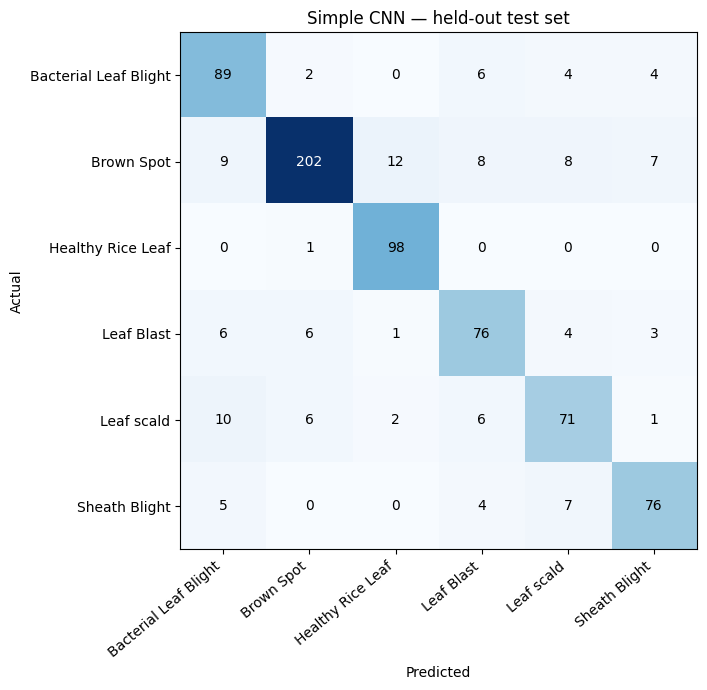

,model,test_accuracy,test_images,previous_split_imported
0,MobileNetV3 (supplied notebook),0.893733,734,False
1,Simple CNN (this run),0.833787,734,False


Historical reference only: identical split membership has not been verified.


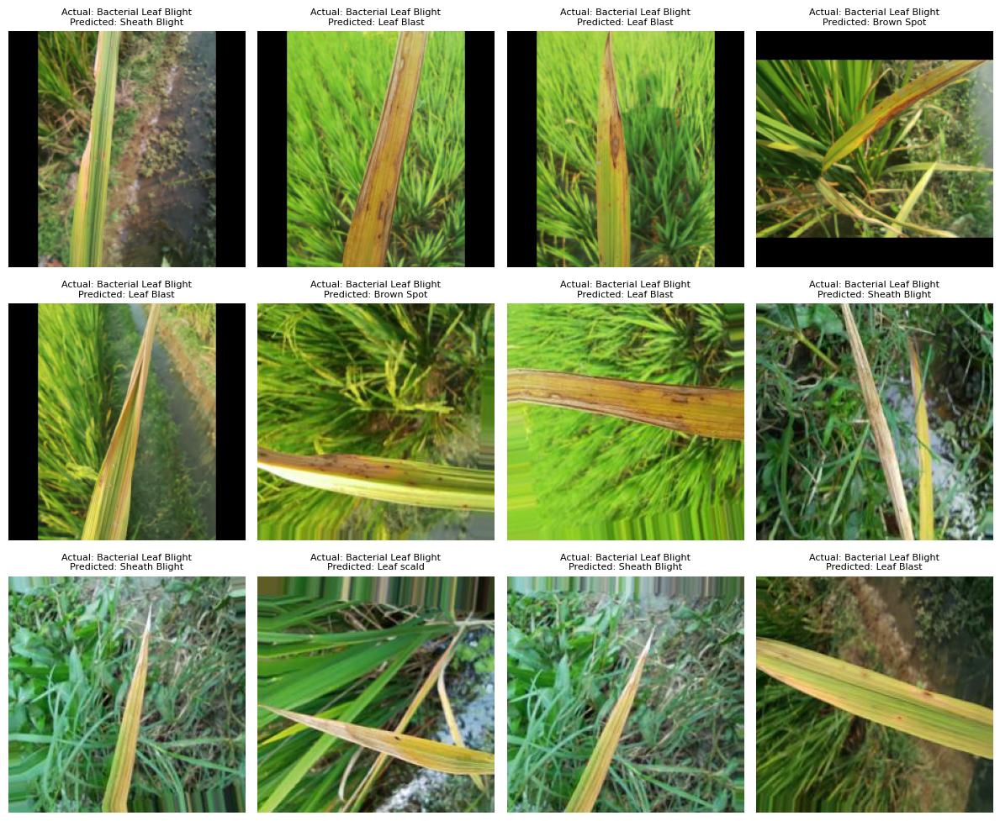

In [15]:
test_probabilities = predict_frame(best_model, test_frame)
test_results = {"simple_cnn": metrics_for(test_frame, test_probabilities)}
test_variants = {"simple_cnn": test_probabilities}
if mobile_status["validated"]:
    mobile_test = tflite_predict(mobile_path, test_frame)
    test_results["tflite"] = metrics_for(test_frame, mobile_test)
    test_variants["tflite"] = mobile_test
write_json(REPORT_DIR / "test_metrics.json", test_results)
display(pd.DataFrame(test_results).transpose())
for name, probabilities in test_variants.items():
    save_predictions(test_frame, probabilities, REPORT_DIR / f"test_{name}_predictions.csv")
    report = classification_report(
        test_frame.label_id, probabilities.argmax(1), labels=list(range(6)),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    pd.DataFrame(report).transpose().to_csv(REPORT_DIR / f"classification_report_{name}.csv")
display(pd.read_csv(REPORT_DIR / "classification_report_simple_cnn.csv", index_col=0))

matrix = confusion_matrix(test_frame.label_id, test_probabilities.argmax(1), labels=list(range(6)))
fig, axis = plt.subplots(figsize=(9, 7))
axis.imshow(matrix, cmap="Blues")
for (row, column), value in np.ndenumerate(matrix):
    axis.text(column, row, str(value), ha="center", va="center", color="white" if value > matrix.max()/2 else "black")
axis.set(xticks=range(6), yticks=range(6), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
         xlabel="Predicted", ylabel="Actual", title="Simple CNN — held-out test set")
plt.setp(axis.get_xticklabels(), rotation=40, ha="right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "confusion_matrix.png", dpi=160)
plt.show()

comparison = pd.DataFrame([
    {"model": "MobileNetV3 (supplied notebook)", "test_accuracy": 0.893733, "test_images": 734},
    {"model": "Simple CNN (this run)", "test_accuracy": test_results["simple_cnn"]["accuracy"], "test_images": len(test_frame)},
])
comparison["previous_split_imported"] = PREVIOUS_SPLIT_CSV is not None
comparison.to_csv(REPORT_DIR / "historical_comparison.csv", index=False)
display(comparison)
if PREVIOUS_SPLIT_CSV is None:
    print("Historical reference only: identical split membership has not been verified.")
else:
    print("Split matched to the supplied CSV. Ensure that CSV belongs to the quoted MobileNetV3 run.")
errors = np.flatnonzero(test_probabilities.argmax(axis=1) != test_frame.label_id.to_numpy())
if len(errors):
    fig, axes = plt.subplots(3, 4, figsize=(12, 10))
    for axis in axes.flat:
        axis.axis("off")
    for axis, index in zip(axes.flat, errors[:12]):
        row = test_frame.iloc[index]
        axis.imshow(Image.open(row.image_path))
        axis.set_title(
            f"Actual: {row.label}\nPredicted: {CLASS_NAMES[test_probabilities[index].argmax()]}",
            fontsize=8,
        )
    fig.tight_layout()
    fig.savefig(REPORT_DIR / "test_errors.png", dpi=140)
    plt.show()
else:
    print("No test errors. Independently verify labels and leakage before claiming perfect performance.")


## 12 · Package the trained model and download
The bundle contains the best `.keras` model, class order, prediction script, preprocessing instructions,
configuration, split manifest, charts and evaluation reports. A `.tflite` file is included only
if it passed validation. It does not include your dataset or training-resume backups.

To predict later: install `inference_requirements.txt`, then run
`python predict.py /path/to/leaf.jpg` from the extracted bundle folder.
The softmax scores are uncalibrated six-class scores; they do not detect unsupported diseases or non-rice images.


In [16]:
PREDICT_SOURCE = '"""Reference Keras prediction. Usage: python predict.py /path/to/photo.jpg"""\nimport json\nimport os\nimport sys\nfrom pathlib import Path\n\nos.environ["KERAS_BACKEND"] = "tensorflow"\nimport numpy as np\nimport tensorflow as tf\nfrom PIL import Image, ImageOps\n\n\ndef prepare_image(path):\n    with Image.open(path) as source:\n        image = ImageOps.exif_transpose(source)\n        if image.mode in ("RGBA", "LA") or "transparency" in image.info:\n            rgba = image.convert("RGBA")\n            image = Image.alpha_composite(\n                Image.new("RGBA", rgba.size, (0, 0, 0, 255)), rgba)\n        image = image.convert("RGB")\n        image = ImageOps.contain(image, (224, 224), Image.Resampling.BILINEAR)\n        canvas = Image.new("RGB", (224, 224), (0, 0, 0))\n        canvas.paste(image, ((224 - image.width) // 2, (224 - image.height) // 2))\n        return np.asarray(canvas, dtype=np.float32)[None]\n\n\ndef predict(path, model_directory=None):\n    folder = Path(model_directory or Path(__file__).parent)\n    labels = json.loads((folder / "class_names.json").read_text())\n    model = tf.keras.models.load_model(folder / "rice_leaf_simple_cnn.keras", compile=False)\n    scores = model.predict(prepare_image(path), verbose=0)[0]\n    order = np.argsort(scores)[::-1]\n    return {\n        "predicted_class": labels[int(order[0])],\n        "model_score": float(scores[order[0]]),\n        "top_three": [{"class": labels[int(i)], "model_score": float(scores[i])}\n                      for i in order[:3]],\n        "note": "Uncalibrated closed-set scores; not a confirmed diagnosis or unknown-image detector.",\n    }\n\n\nif __name__ == "__main__":\n    print(json.dumps(predict(sys.argv[1]), indent=2))\n'


In [17]:
write_json(EXPORT_DIR / "preprocessing.json", {
    "input_shape": [1, 224, 224, 3], "dtype": "float32", "color": "RGB", "input_range": [0, 255],
    "orientation": "Apply EXIF transpose; composite transparency on black.",
    "resize": "Pillow ImageOps.contain, bilinear; center on black 224x224 canvas using floor offsets.",
    "normalization": "Rescaling(1/255) is inside the model. Do not normalize twice.",
    "output": "Six softmax scores in class_names.json order.",
})
(EXPORT_DIR / "predict.py").write_text(PREDICT_SOURCE, encoding="utf-8")
(EXPORT_DIR / "inference_requirements.txt").write_text(
    "tensorflow==2.20.0\nkeras==3.11.3\nnumpy==2.2.6\nPillow==11.3.0\n", encoding="utf-8")
shutil.copy2(config_path, EXPORT_DIR / "experiment_config.json")
model_card = f"""# Rice leaf simple CNN

Architecture: 3x3 convolutions with 32, 64, 128 filters; ReLU and 2x2 max pooling after each;
global average pooling; Dense 128/ReLU; dropout {DROPOUT}; Dense 6/Softmax.
110,534 trainable parameters. Random initialization, no pretrained weights.
Selection: lowest validation loss, including L2 penalty {L2_REGULARIZATION}.
Train / validation / test images: {len(train_frame)} / {len(validation_frame)} / {len(test_frame)}.
Class order: {json.dumps(CLASS_NAMES)}.
Test accuracy: {test_results['simple_cnn']['accuracy']:.6f}.
Test macro F1: {test_results['simple_cnn']['macro_f1']:.6f}.
Old split imported: {PREVIOUS_SPLIT_CSV is not None}.
Mobile export validated: {mobile_status['validated']}.
Dataset archive SHA256: {archive_sha256}.

Use predict.py for the reference EXIF/RGB/aspect-preserving preprocessing.
Input is float32 [0,255]; the model normalizes internally.
This is an internal held-out evaluation, not independent field validation.
One principal supported condition per photograph is assumed. Capture metadata coverage:
{grouped.capture_group_known.mean():.1%}. Near-duplicate grouping cannot discover every related photo.
Scores are uncalibrated and unsupported conditions/non-rice inputs may receive high scores.
Record the dataset source, licence and label review separately.

Files: rice_leaf_simple_cnn.keras, class_names.json, labels.txt, predict.py,
preprocessing.json, inference_requirements.txt, experiment_config.json and reports/.
rice_leaf_simple_cnn.tflite is included only after a successful float32 parity check.
Training epoch backups remain in the Modal run directory and are not in this bundle.
"""
(EXPORT_DIR / "MODEL_CARD.md").write_text(model_card, encoding="utf-8")
bundle_path = RUN_DIR / "rice_leaf_simple_cnn_bundle.zip"
checksums = []
with zipfile.ZipFile(bundle_path, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as bundle:
    for folder, prefix in ((EXPORT_DIR, ""), (REPORT_DIR, "reports/")):
        for path in sorted(folder.rglob("*")):
            if not path.is_file() or (path.suffix == ".tflite" and not mobile_status["validated"]):
                continue
            relative = prefix + path.relative_to(folder).as_posix()
            bundle.write(path, relative)
            checksums.append({"path": relative, "sha256": sha256_file(path)})
    bundle.writestr("file_checksums.json", json.dumps(checksums, indent=2))
with zipfile.ZipFile(bundle_path) as bundle:
    assert bundle.testzip() is None, "Bundle integrity check failed."
if hasattr(os, "sync"):
    os.sync()
print("DOWNLOAD THIS FILE FROM THE MODAL FILES PANEL:")
print(bundle_path)
print(f"Size: {bundle_path.stat().st_size / 1024**2:.2f} MiB")
print("SHA256:", sha256_file(bundle_path))


DOWNLOAD THIS FILE FROM THE MODAL FILES PANEL:
/root/rice_simple_cnn/runs/simple_cnn_run_01/rice_leaf_simple_cnn_bundle.zip
Size: 7.50 MiB
SHA256: 8101bfac706b5b201c006da878bb8b1b515846415a898e7bea2eeef7792ef8b4


## 13 · Optional: predict one new photograph


In [18]:
PHOTO_PATH = None  # Example: VOLUME_ROOT / "new_leaf.jpg"
if PHOTO_PATH is not None:
    rgb = open_rgb(PHOTO_PATH)
    image = np.asarray(letterbox(rgb), dtype=np.float32)[None]
    probabilities = best_model.predict(image, verbose=0)[0]
    display(pd.DataFrame({
        "class": CLASS_NAMES, "model_score": probabilities,
    }).sort_values("model_score", ascending=False).head(3))
    plt.imshow(rgb)
    plt.axis("off")
    plt.show()
else:
    print("Optional: set PHOTO_PATH to test one new image.")


Optional: set PHOTO_PATH to test one new image.


In [19]:
from pathlib import Path
from datetime import datetime, timezone
import shutil
import zipfile
from IPython.display import display, FileLink

# Uses paths already defined in your notebook.
export_dir = Path(EXPORT_DIR)
report_dir = Path(REPORT_DIR)
run_dir = Path(RUN_DIR)

model_path = export_dir / "rice_leaf_simple_cnn.keras"
if not model_path.is_file():
    raise FileNotFoundError(
        "Trained model not found. Complete the training cell first."
    )

if not (report_dir / "test_metrics.json").is_file():
    raise FileNotFoundError(
        "Test results not found. Complete the final evaluation cell first."
    )

# Create a separate final outputs folder.
timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
final_folder = run_dir / f"Rice_Leaf_Final_Outputs_{timestamp}"
final_folder.mkdir(exist_ok=False)

# Copy model files and evaluation reports.
shutil.copytree(export_dir, final_folder / "model")
shutil.copytree(report_dir, final_folder / "reports")

config_path = run_dir / "experiment_config.json"
if config_path.is_file():
    shutil.copy2(config_path, final_folder / config_path.name)

# Exclude mobile exports unless they passed validation.
status_path = report_dir / "mobile_export_status.json"
import json
mobile_validated = (
    json.loads(status_path.read_text()).get("validated", False)
    if status_path.is_file() else False
)
if not mobile_validated:
    for file in (final_folder / "model").rglob("*.tflite"):
        file.unlink()

# ZIP the complete final outputs folder.
zip_path = Path(shutil.make_archive(
    str(final_folder),
    "zip",
    root_dir=final_folder.parent,
    base_dir=final_folder.name,
))

# Verify the ZIP.
with zipfile.ZipFile(zip_path) as archive:
    damaged_file = archive.testzip()
    if damaged_file:
        raise RuntimeError(f"ZIP verification failed: {damaged_file}")

print("Final outputs ZIP is ready!")
print(f"Size: {zip_path.stat().st_size / (1024 ** 2):.2f} MB")
print(f"Download file: {zip_path}")

display(FileLink(str(zip_path), result_html_prefix="Download ZIP: "))

Final outputs ZIP is ready!
Size: 7.51 MB
Download file: /root/rice_simple_cnn/runs/simple_cnn_run_01/Rice_Leaf_Final_Outputs_20261017_201614_860918.zip


/root/rice_simple_cnn/runs/simple_cnn_run_01/Rice_Leaf_Final_Outputs_20261017_201614_860918.zip

In [20]:
from pathlib import Path
from IPython.display import display, HTML
import base64
import html

# zip_path was created by the previous cell.
file_to_download = Path(zip_path)

if not file_to_download.is_file():
    raise FileNotFoundError("Run the ZIP creation cell first.")

encoded_zip = base64.b64encode(
    file_to_download.read_bytes()
).decode("ascii")

filename = html.escape(file_to_download.name, quote=True)

display(HTML(f"""
<a
    href="data:application/zip;base64,{encoded_zip}"
    download="{filename}"
    style="
        display: inline-block;
        padding: 14px 22px;
        background: #15803d;
        color: white;
        border-radius: 8px;
        text-decoration: none;
        font-weight: bold;
    "
>
    Download ZIP to my computer
</a>
"""))

## Troubleshooting
| Situation | Action |
|---|---|
| Volume or ZIP not found | Copy the actual path from the Files panel into step 2. |
| No GPU visible | Select a GPU, install in the new container and restart the kernel. |
| GPU out of memory | Set BATCH_SIZE=16 and a new RUN_NAME. |
| Kernel interrupted | Rerun setup and data/model cells with unchanged settings, then training. |
| Previous split mismatch | Use the same original dataset and its exported split_manifest.csv. |
| Settings changed | Use a new RUN_NAME; keep the earlier experiment intact. |
| Wrong/missing classes | Check the six folder names and reports/rejected_images.csv. |
| Validation score stays low | Review labels/previews, try learning rate 0.0003 in a new run, and compare validation. |
| TFLite conversion failed | Download the Keras bundle; inspect reports/conversion.log and mobile_export_status.json. |

For a project report, describe the measured result rather than predicting that this CNN will outperform
MobileNetV3. Keep the test set fixed and use validation for all training decisions.
